# Freight Rate Prediction Assessment

This notebook reviews the supplied datasets, documents data quality, inspects the chronological holdout results, checks the generated CSV outputs, and displays the chart created by the provided scorer.

The full model-training and prediction workflow is implemented in `src/` and can be reproduced with the CLI command in the root `README.md`. Run this notebook from the repository root or from the `notebooks/` folder.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
train = pd.read_csv(DATA / "train_test.csv")
validation = pd.read_csv(DATA / "validation.csv")
template = pd.read_csv(DATA / "validation_predictions_template.csv")
december_input = pd.read_csv(DATA / "december_chart_inputs.csv")
train["date"] = pd.to_datetime(train["date"])
validation["date"] = pd.to_datetime(validation["date"])
december_input["date"] = pd.to_datetime(december_input["date"])
print("Development:", train.shape, train.date.min().date(), "to", train.date.max().date())
print("Validation:", validation.shape, validation.date.min().date(), "to", validation.date.max().date())
print("December scenario:", december_input.shape)

Development: (48000, 14) 2025-01-01 to 2025-10-31
Validation: (12000, 13) 2025-11-01 to 2025-12-31
December scenario: (31, 7)


In [2]:
# Data quality checks
quality = pd.DataFrame({
    "count": [
        len(train), train.date.nunique(), train.pickup.nunique(), train.delivery.nunique(),
        train.equipment.nunique(), train.weight.isna().sum(), train.market_index.isna().sum(),
        train.weight.lt(0).sum(), train.weight.ge(47500).sum(),
        train.drop(columns=["load_id"]).duplicated().sum(),
    ]
}, index=[
    "development rows", "unique dates", "pickup cities", "delivery cities",
    "equipment types", "missing weight", "missing market_index",
    "negative weights", "weights at 47,500 cap", "duplicate records excluding ID",
])
display(quality)
display(train.posted_rate.describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).to_frame("posted_rate"))
display(validation.date.dt.to_period("M").value_counts().sort_index().rename("rows").to_frame())

,count
development rows,48000
unique dates,304
pickup cities,64
delivery cities,64
equipment types,3
missing weight,300
missing market_index,374
negative weights,292
"weights at 47,500 cap",1191
duplicate records excluding ID,0


,posted_rate
count,48000.000000
mean,2373.980682
std,1486.493245
min,57.220000
1%,327.168800
5%,599.738500
25%,1251.555000
50%,2030.760000
75%,3330.750000
95%,4953.766500


,rows
date,
2025-11,5836
2025-12,6164


eda_target_distribution.png


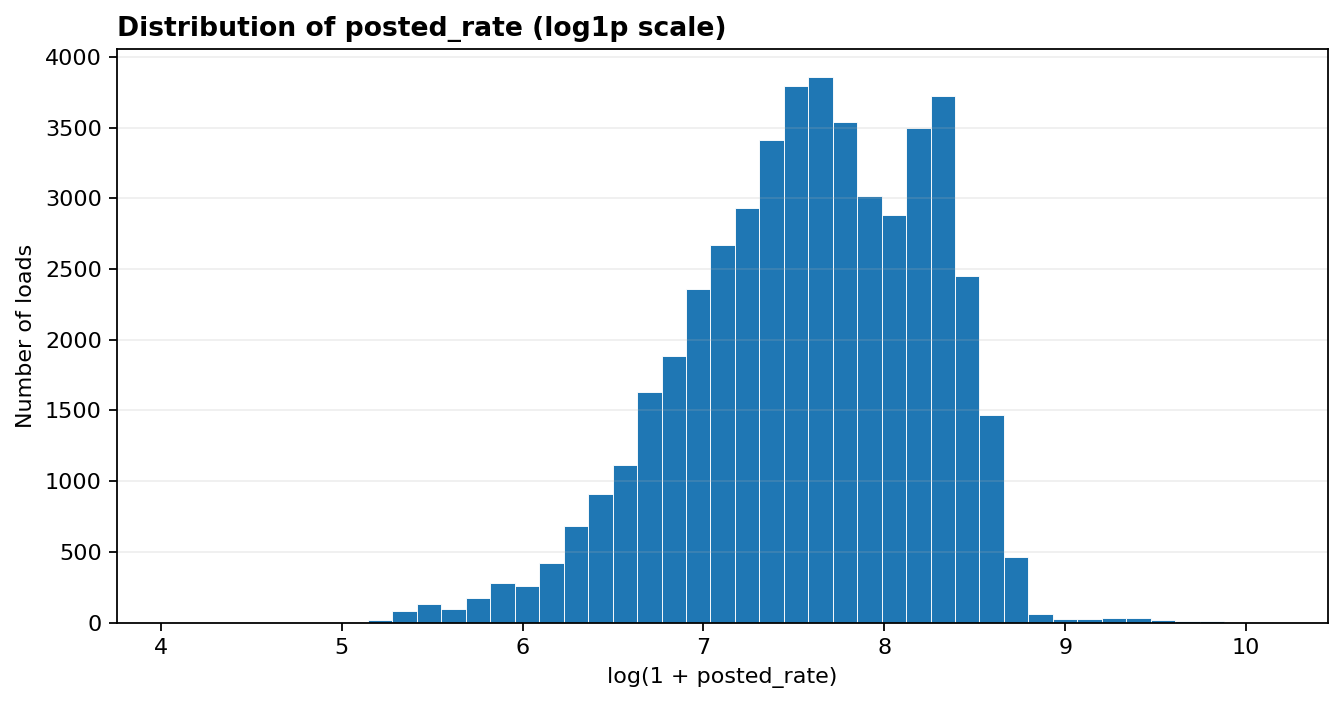

eda_rate_vs_distance.png


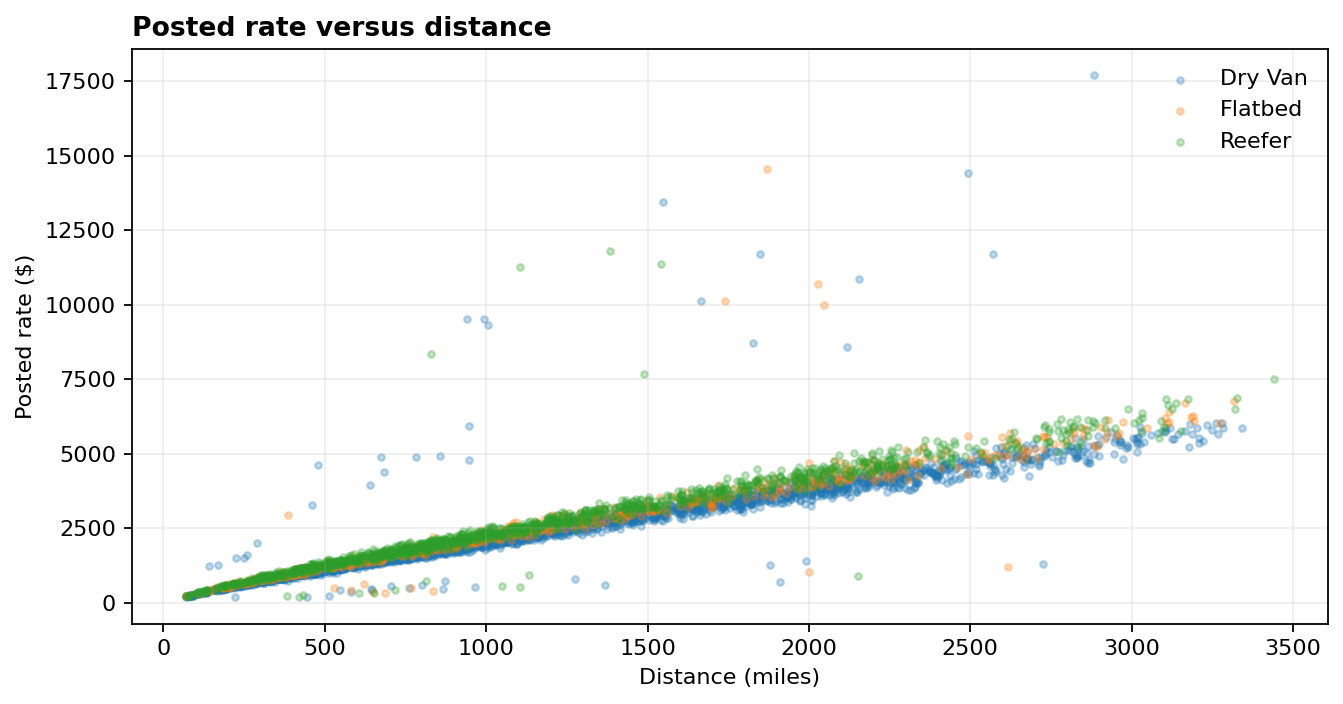

eda_monthly_target.png


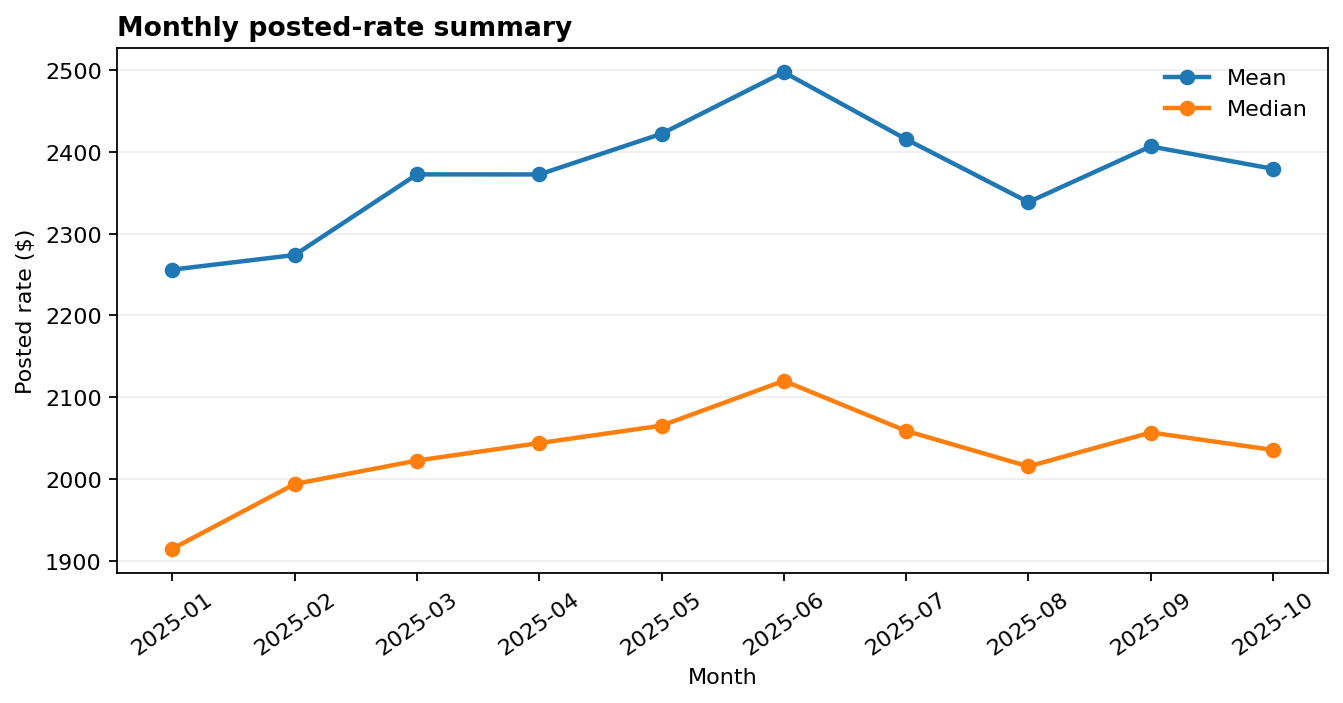

In [3]:
# Key EDA plots generated by the preprocessing / pipeline scripts
for filename in ["eda_target_distribution.png", "eda_rate_vs_distance.png", "eda_monthly_target.png"]:
    print(filename)
    display(Image(filename=str(ROOT / "outputs/charts" / filename)))

In [4]:
# Chronological holdout results
model_comparison = pd.read_csv(ROOT / "outputs/metrics/model_comparison.csv")
display(model_comparison.round(3))
secondary = json.loads((ROOT / "outputs/metrics/september_secondary_holdout.json").read_text())
print(json.dumps(secondary, indent=2))

,Model,MAE,RMSE,R2,MAPE_pct,Best iteration
0,Mean baseline,1179.796,1528.567,-0.000,86.345,NaN
1,Ridge regression,141.730,649.653,0.819,8.445,NaN
2,LightGBM,150.876,666.235,0.810,8.065,118.0
3,CatBoost (raw target),125.677,649.054,0.820,7.154,271.0
4,Ridge (per-mile target),119.191,645.110,0.822,5.385,NaN
5,CatBoost (log target),109.385,646.232,0.821,5.191,419.0
6,Final 50/50 ensemble,108.132,644.527,0.822,5.014,NaN


{
  "n_train": 38477,
  "n_valid": 4670,
  "period": "2025-09-01 through 2025-09-30",
  "Ridge per-mile": {
    "MAE": 115.03860186043224,
    "RMSE": 620.5393398377936,
    "R2": 0.8340581757828682,
    "MAPE_pct": 4.452037173574167
  },
  "CatBoost log-target": {
    "MAE": 114.13201203536178,
    "RMSE": 620.0191730160901,
    "R2": 0.8343362605003958,
    "MAPE_pct": 4.573024957907579
  },
  "50/50 ensemble": {
    "MAE": 110.81956561054491,
    "RMSE": 619.4574291949914,
    "R2": 0.8346363106574378,
    "MAPE_pct": 4.333475209366965
  }
}


In [5]:
# Validate files and rerun the official scorer
predictions = pd.read_csv(ROOT / "validation_predictions.csv")
december_predictions = pd.read_csv(ROOT / "december_predictions.csv")
assert list(predictions.columns) == ["load_id", "predicted_rate"]
assert len(predictions) == 12000 and predictions.load_id.is_unique
assert predictions.load_id.astype(str).equals(template.load_id.astype(str))
assert predictions.predicted_rate.notna().all() and (predictions.predicted_rate > 0).all()
assert len(december_predictions) == 31 and december_predictions.predicted_rate.notna().all()
assert pd.to_datetime(december_predictions.date).dt.strftime("%Y-%m-%d").tolist() == pd.date_range("2025-12-01", "2025-12-31").strftime("%Y-%m-%d").tolist()
print("Prediction rows:", len(predictions))
print("Prediction min / median / max:", predictions.predicted_rate.min(), predictions.predicted_rate.median(), predictions.predicted_rate.max())
print("December prediction min / mean / max:", december_predictions.predicted_rate.min(), december_predictions.predicted_rate.mean(), december_predictions.predicted_rate.max())
subprocess.run([sys.executable, str(ROOT / "score.py"), "--predictions", str(ROOT / "validation_predictions.csv"), "--december-predictions", str(ROOT / "december_predictions.csv"), "--output-dir", str(ROOT / "scorer_results")], cwd=ROOT, check=True)
print("Official scorer passed.")

Prediction rows: 12000
Prediction min / median / max: 176.35393258550403 2078.5442971376406 6936.876039805566
December prediction min / mean / max: 835.5299631969413 844.0915964740251 854.4705329051199


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: /mnt/data/freight-rate-prediction/scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


Official scorer passed.


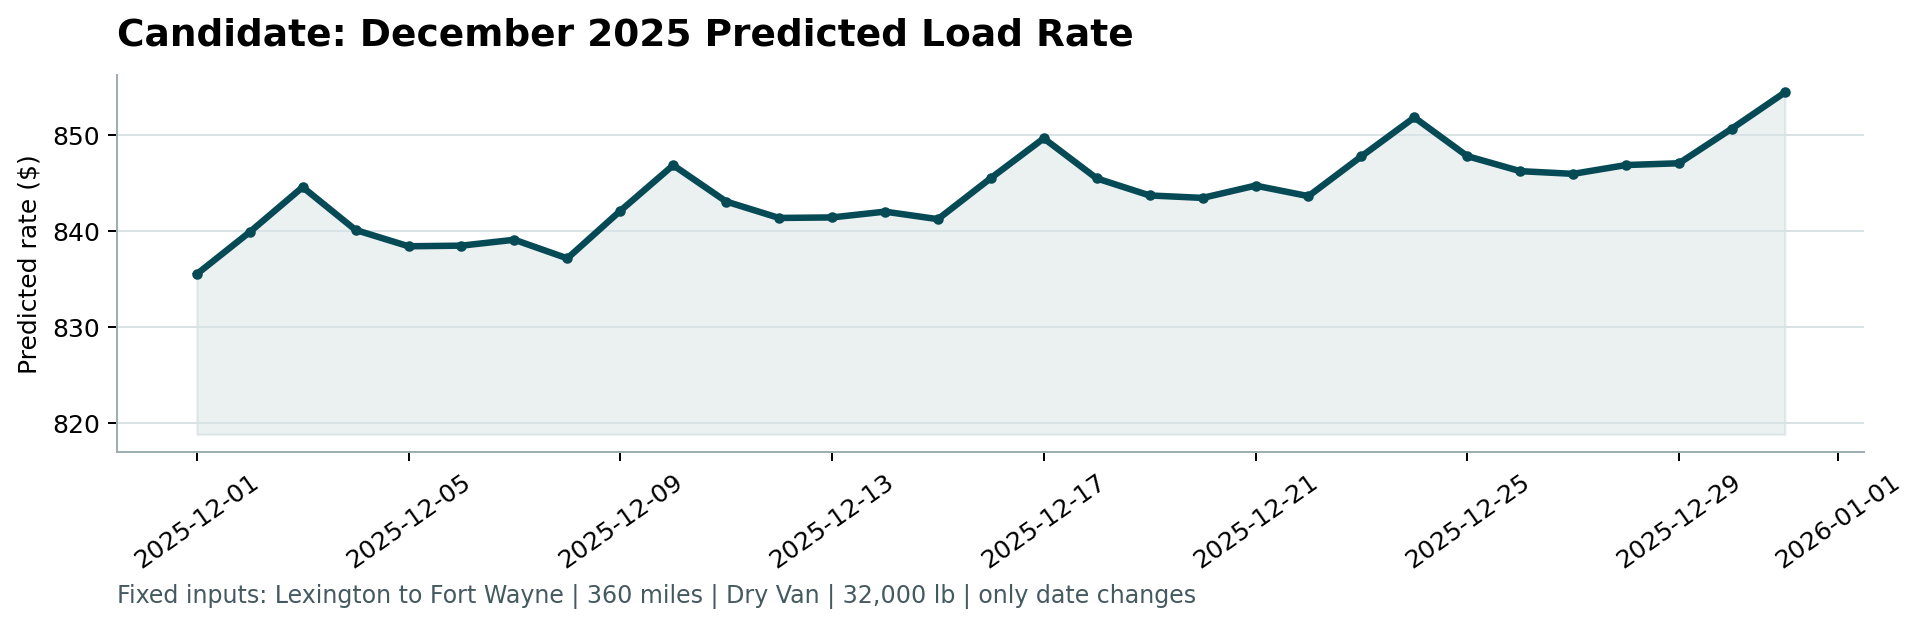

In [6]:
# Official December chart generated by score.py
shutil_path = ROOT / "scorer_results/candidate_december.png"
display(Image(filename=str(shutil_path)))

## Interpretation and limitations

The October and September figures are historical chronological holdout metrics. The November-December validation file has no target labels, so its true prediction error cannot be calculated locally. The scorer validates output shape and the fixed December scenario; Spotter calculates the final competition metric after submission. The original assessment PDF was not among the uploaded files, so confirm its scoring metric and data-sharing rules before publishing the repository.